# 🚲 Os quatro entregadores: Value Iteration, Policy Iteration, Monte Carlo e TD

Este notebook acompanha os **slides 76 a 85** da aula ("Como o agente aprende").

**A pergunta-chave (slide 77):** o agente **conhece as regras do mundo**, isto é, quem paga o quê e para onde cada ação leva?

| | Personagem | Método | Conhece o mapa? | Como aprende |
|---|---|---|---|---|
| 🗺️ | **O Cartógrafo** | Value Iteration | ✅ sim | Calcula no papel o valor de cada casa antes de dar um passo |
| 🔧 | **O Treinador** | Policy Iteration | ✅ sim | Testa a estratégia, corrige o ponto fraco e testa de novo |
| 🍽️ | **O Crítico** | Monte Carlo | ❌ não | Só dá a nota depois de terminar a refeição inteira |
| 🚗 | **O Motorista** | Diferença Temporal | ❌ não | Corrige a previsão de chegada a cada esquina |

**O cenário de todos eles:** um entregador de bicicleta numa avenida com 5 quarteirões. O mesmo cenário para os quatro, para que dê para comparar.

```
  [Depósito]   A    B    C    D    E   [Cliente 🏁]
   fim · 0                                fim · +1
```

### Roteiro (≈ 30 min)

| Seção | Personagem | Slides | Tempo |
|---|---|---|---|
| 1 | 🗺️ O Cartógrafo: o boato se espalha | 78–79 | 5 min |
| 2 | 🔧 O Treinador: avaliar e melhorar | 80 | 5 min |
| 3 | 🍽️ O Crítico: nota só no fim | 81 | 5 min |
| 4 | 🚗 O Motorista: a volta para casa (**item 1 do slide 85**) | 83–84 | 5 min |
| 5 | Crítico × Motorista: o passeio na avenida (**item 2 do slide 85**) | 82 | 5 min |
| 6 | A corrida (**item 3 do slide 85**) | 85 | 5 min |

> **Como usar:** rode as células em ordem (Shift + Enter). Sempre que aparecer **🤔 Palpite**, a dupla escreve a aposta **antes** de rodar.

### 🎯 Aquecimento: quem é quem?

Associe cada situação a um dos quatro personagens:

1. O Waze recalculando a hora de chegada a cada semáforo.
2. Um gerente que só avalia a campanha de marketing quando ela termina.
3. Um engenheiro que calcula a melhor rota no mapa antes de sair de casa.
4. Um técnico que testa um esquema tático, corrige o ponto fraco e testa de novo.

<details>
<summary><b>Ver respostas</b></summary>

1 → 🚗 Motorista (TD) · 2 → 🍽️ Crítico (Monte Carlo) · 3 → 🗺️ Cartógrafo (Value Iteration) · 4 → 🔧 Treinador (Policy Iteration)
</details>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib import animation
from IPython.display import HTML

br = lambda x, d=2: f'{x:.{d}f}'.replace('.', ',')   # número no formato brasileiro

### A avenida em código

- **Estados:** os quarteirões A, B, C, D e E (índices 0 a 4).
- **Ações:** `+1` (→, rumo ao cliente) e `−1` (←, rumo ao depósito).
- **Recompensa:** +1 ao chegar ao **Cliente**; 0 em todo o resto. Chegar ao Cliente ou ao Depósito **termina** o episódio.

A função `passo` é o **modelo do mundo**, o "mapa". O Cartógrafo e o Treinador podem consultá-la à vontade. O Crítico e o Motorista **não**: eles só descobrem o mundo andando por ele.

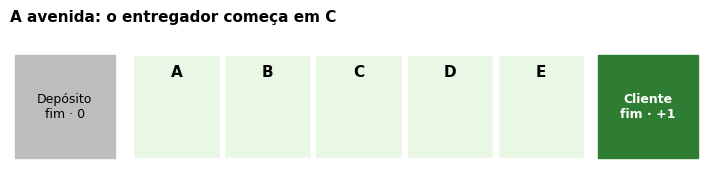

In [2]:
NOMES = ['A', 'B', 'C', 'D', 'E']
N = len(NOMES)
SETA = {+1: '→', -1: '←'}


def passo(s, a):
    '''O MAPA: do quarteirão s, andar a (+1 ou −1). Devolve (próximo, recompensa, terminou).'''
    s2 = s + a
    if s2 == N:
        return s2, 1.0, True      # chegou ao Cliente
    if s2 < 0:
        return s2, 0.0, True      # voltou ao Depósito
    return s2, 0.0, False


def desenhar_avenida(ax, V=None, politica=None, titulo='', destaque=()):
    '''Desenha a avenida com o valor (número) e a ação (seta) de cada quarteirão.'''
    ax.set_xlim(-1.35, 6.3); ax.set_ylim(-.1, 1.25); ax.axis('off')
    ax.add_patch(Rectangle((-1.3, 0), 1.1, 1, color='#BDBDBD'))
    ax.text(-.75, .5, 'Depósito\nfim · 0', ha='center', va='center', fontsize=9)
    ax.add_patch(Rectangle((5.1, 0), 1.1, 1, color='#2E7D32'))
    ax.text(5.65, .5, 'Cliente\nfim · +1', ha='center', va='center', fontsize=9, color='white', fontweight='bold')
    for s in range(N):
        v = 0.0 if V is None else V[s]
        ax.add_patch(Rectangle((s, 0), .95, 1, facecolor=plt.cm.Greens(.1 + .6 * min(max(v, 0), 1)),
                               edgecolor='#E91E63' if s in destaque else 'white', lw=4 if s in destaque else 1))
        ax.text(s + .475, .84, NOMES[s], ha='center', va='center', fontsize=11, fontweight='bold')
        if V is not None:
            ax.text(s + .475, .52, br(v), ha='center', va='center', fontsize=12)
        if politica is not None:
            ax.text(s + .475, .2, SETA[politica[s]], ha='center', va='center', fontsize=18)
    ax.set_title(titulo, fontsize=11, fontweight='bold', loc='left')


fig, ax = plt.subplots(figsize=(9, 1.8))
desenhar_avenida(ax, titulo='A avenida: o entregador começa em C')
plt.show()

---
## 1. 🗺️ O Cartógrafo — Value Iteration (slides 78 e 79)

O Cartógrafo **tem o mapa**. Antes de pedalar, ele calcula no papel quanto vale cada quarteirão, rodada após rodada, com a equação de Bellman:

$$V(s) \leftarrow \max_a \big[\,R(s,a) + \gamma \cdot V(s')\,\big]$$

**A receita (slide 78):**

1. Comece com V = 0 em todos os quarteirões.
2. **Varredura:** aplique Bellman em cada quarteirão.
3. Repita até ninguém mudar mais.
4. Extraia π*: em cada quarteirão, a ação de maior valor.

**Analogia (slide 79): um boato que se espalha.** A notícia "o Cliente paga +1" nasce em E e, a cada rodada, anda **um quarteirão** para trás, perdendo 10% (γ = 0,9).

> 🤔 **Palpite:** em que rodada a notícia chega ao quarteirão A? Quanto ela vale lá?

In [3]:
def value_iteration(gamma=0.9, theta=1e-6):
    '''Varre todos os quarteirões até ninguém mudar. Devolve (V*, π*, histórico de cada rodada).'''
    V = np.zeros(N)
    historico = [V.copy()]
    while True:
        novo = np.array([max(valor_acao(V, s, a, gamma) for a in (+1, -1)) for s in range(N)])
        historico.append(novo)
        if np.max(np.abs(novo - V)) < theta:     # ninguém mudou: convergiu
            break
        V = novo
    politica = [max((+1, -1), key=lambda a: valor_acao(V, s, a, gamma)) for s in range(N)]
    return V, politica, historico


def valor_acao(V, s, a, gamma):
    '''R + γ·V(s'): o que ganho agora + o que vale onde chego (no fim, o futuro vale 0).'''
    s2, r, fim = passo(s, a)
    return r + (0.0 if fim else gamma * V[s2])


GAMMA = 0.9   # 👈 depois troque para 0.5 e rode de novo
V_vi, pi_vi, hist = value_iteration(GAMMA)

print(f"{'Rodada':<8}" + ''.join(f'{n:>7}' for n in NOMES))
for k, V in enumerate(hist[1:], start=1):
    fim = '   ← ninguém mudou: convergiu!' if k == len(hist) - 1 else ''
    print(f'{k:<8}' + ''.join(f'{br(v):>7}' for v in V) + fim)
print(f"{'π*':<8}" + ''.join(f'{SETA[a]:>7}' for a in pi_vi))

Rodada        A      B      C      D      E
1          0,00   0,00   0,00   0,00   1,00
2          0,00   0,00   0,00   0,90   1,00
3          0,00   0,00   0,81   0,90   1,00
4          0,00   0,73   0,81   0,90   1,00
5          0,66   0,73   0,81   0,90   1,00
6          0,66   0,73   0,81   0,90   1,00   ← ninguém mudou: convergiu!
π*            →      →      →      →      →


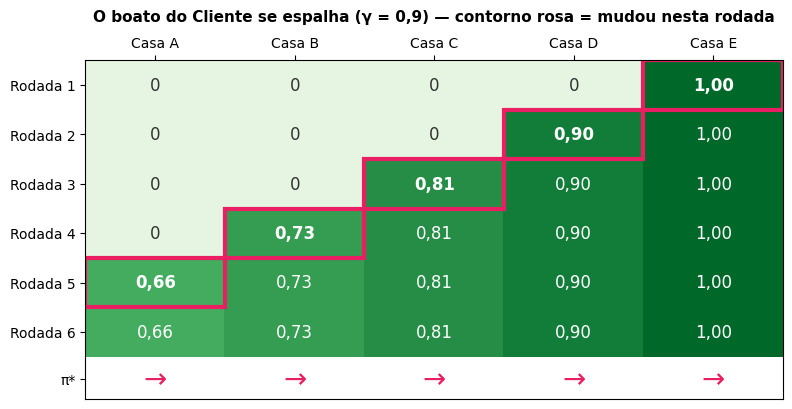

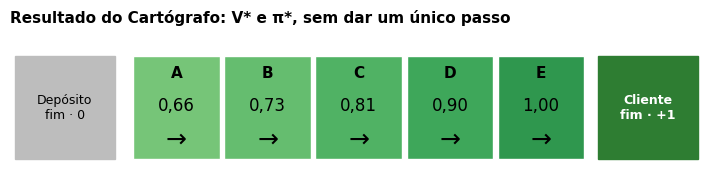

In [4]:
# A tabela do slide 79, desenhada: em destaque, quem mudou em cada rodada
rod = np.array(hist[1:])
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.imshow(rod, cmap='Greens', vmin=-.15, vmax=1.15, aspect='auto')
for k in range(len(rod)):
    for s in range(N):
        mudou = abs(rod[k, s] - hist[k][s]) > 1e-9
        ax.text(s, k, br(rod[k, s]) if rod[k, s] else '0', ha='center', va='center', fontsize=12,
                fontweight='bold' if mudou else 'normal', color='white' if rod[k, s] > .6 else '#333')
        if mudou:
            ax.add_patch(Rectangle((s - .5, k - .5), 1, 1, fill=False, edgecolor='#E91E63', lw=3))
for s in range(N):
    ax.text(s, len(rod) - .05, SETA[pi_vi[s]], ha='center', va='center', fontsize=20, color='#E91E63')
ax.set_ylim(len(rod) + .35, -.5)
ax.set_xticks(range(N), [f'Casa {n}' for n in NOMES]); ax.xaxis.tick_top()
ax.set_yticks(list(range(len(rod))) + [len(rod) - .05],
              [f'Rodada {k + 1}' for k in range(len(rod))] + ['π*'])
ax.set_title(f'O boato do Cliente se espalha (γ = {br(GAMMA, 1)}) — contorno rosa = mudou nesta rodada',
             fontsize=11, fontweight='bold', pad=28)
plt.show()

fig, ax = plt.subplots(figsize=(9, 1.8))
desenhar_avenida(ax, V_vi, pi_vi, titulo='Resultado do Cartógrafo: V* e π*, sem dar um único passo')
plt.show()

**🔎 O que observar**
- **Uma casa por rodada:** na rodada 1 só E sabe do Cliente; na 5, a notícia chega a A. Na rodada 6 ninguém muda: **convergiu**.
- **O valor cai 10% a cada casa:** 1 → 0,9 → 0,81 → 0,73 → 0,66, a mesma sequência da grade 4×3 (slides 62–64).
- **A política sai de graça no fim:** em cada casa, seguir a seta para o vizinho de maior valor.

### 🤔 Pergunta do slide 79: e se γ = 0,5? Até onde o boato chegaria "forte"?

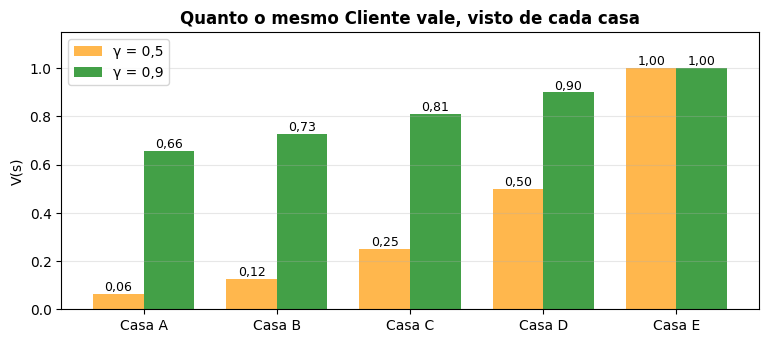

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.6))
x, w = np.arange(N), .38
for desloc, g, cor in [(-w / 2, .5, '#FFB74D'), (w / 2, .9, '#43A047')]:
    V, _, h = value_iteration(g)
    barras = ax.bar(x + desloc, V, w, color=cor, label=f'γ = {br(g, 1)}')
    ax.bar_label(barras, labels=[br(v) for v in V], fontsize=9)
ax.set_xticks(x, [f'Casa {n}' for n in NOMES]); ax.set_ylim(0, 1.15)
ax.set_ylabel('V(s)'); ax.legend(loc='upper left'); ax.grid(axis='y', alpha=.3)
ax.set_title('Quanto o mesmo Cliente vale, visto de cada casa', fontweight='bold')
plt.show()

**🔎 Resposta:** com γ = 0,5, o boato perde **metade** a cada casa. Em A (4 casas antes de E), ele chega com só 0,5⁴ ≈ **0,06**: um agente imediatista quase não "sente" o Cliente lá do começo da avenida. Com γ = 0,9, ainda chega com 0,66.

> **Custo (slide 78):** cada rodada percorre **todos** os estados e ações. Aqui são 5 casas. Num jogo com bilhões de estados, o Cartógrafo nunca terminaria o mapa.

---
## 2. 🔧 O Treinador — Policy Iteration (slide 80)

O Treinador também tem o mapa, mas trabalha de outro jeito. Ele começa com **uma estratégia qualquer** e repete o ciclo:

1. **Avaliar:** com a política **fixa**, calcula quanto vale cada casa ($V^\pi$). Não há max: o agente só segue a regra.
2. **Melhorar:** em cada casa, troca pela ação de maior valor (argmax).
3. **Parou de mudar?** A política é ótima.

**A história:** o chefe chegou com uma regra pronta, `→ → ← → →`. Ela tem um erro bobo: no quarteirão C, mandar voltar.

> 🤔 **Palpite:** quantas rodadas o Treinador leva para consertar a regra do chefe?

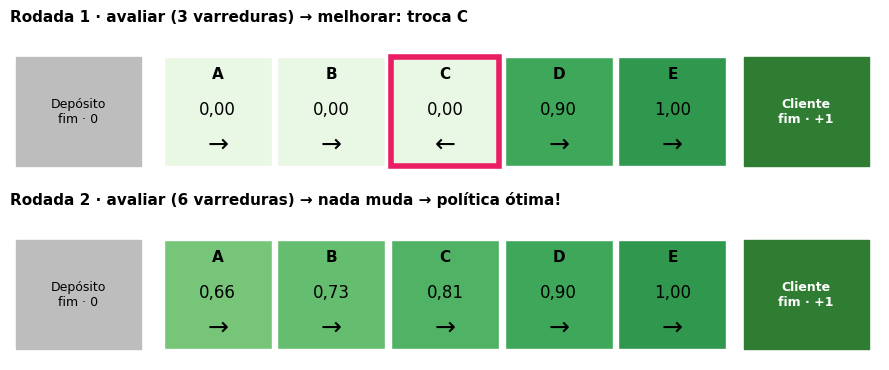

Regra inicial "→ → ← → →": 2 rodada(s) até a política ótima.


In [6]:
def avaliar(politica, gamma=0.9, theta=1e-6):
    '''1 · AVALIAR: V da política fixa (sem max). Devolve (V, número de varreduras).'''
    V, varreduras = np.zeros(N), 0
    while True:
        novo = np.array([valor_acao(V, s, politica[s], gamma) for s in range(N)])
        varreduras += 1
        if np.max(np.abs(novo - V)) < theta:
            return novo, varreduras
        V = novo


def melhorar(V, politica, gamma=0.9):
    '''2 · MELHORAR: em cada casa, troca pela melhor ação (só troca se for estritamente melhor).'''
    nova = list(politica)
    for s in range(N):
        melhor = max((+1, -1), key=lambda a: valor_acao(V, s, a, gamma))
        if valor_acao(V, s, melhor, gamma) > valor_acao(V, s, politica[s], gamma) + 1e-9:
            nova[s] = melhor
    return nova


def policy_iteration(regra, gamma=0.9):
    '''Repete avaliar → melhorar até a política parar de mudar.'''
    politica = [+1 if c == '→' else -1 for c in regra.replace(' ', '')]
    rodadas = []
    while True:
        V, varreduras = avaliar(politica, gamma)
        nova = melhorar(V, politica, gamma)
        mudou = [s for s in range(N) if nova[s] != politica[s]]
        rodadas.append((politica, V, varreduras, mudou))
        if not mudou:
            return rodadas
        politica = nova


def mostrar_treinador(regra):
    rodadas = policy_iteration(regra)
    fig, axes = plt.subplots(len(rodadas), 1, figsize=(9, 1.9 * len(rodadas)), squeeze=False)
    for k, (pol, V, varr, mudou) in enumerate(rodadas):
        acao = ('melhorar: troca ' + ', '.join(NOMES[s] for s in mudou)) if mudou else 'nada muda → política ótima!'
        desenhar_avenida(axes[k, 0], V, pol, destaque=mudou,
                         titulo=f'Rodada {k + 1} · avaliar ({varr} varreduras) → {acao}')
    plt.tight_layout()
    plt.show()
    print(f'Regra inicial "{regra}": {len(rodadas)} rodada(s) até a política ótima.')


mostrar_treinador('→ → ← → →')   # 👈 a regra do chefe

**🔎 O que observar**
- **Rodada 1, avaliar:** com a regra do chefe, C manda para B, e B manda de volta para C. O entregador fica num **vai e vem eterno**, e por isso A, B e C valem 0.
- **Rodada 1, melhorar:** o Treinador vê que, em C, ir para → vale 0,81 em vez de 0, e troca **só o ponto fraco** (contorno rosa).
- **Rodada 2:** nada mais muda, e a política é ótima. Foram **2 rodadas**, mas cada uma é "cara": tem várias varreduras de avaliação dentro.

### 🎮 Desafio: invente a pior regra possível

Troque a regra abaixo e veja quantas rodadas o Treinador precisa. Tente `'← ← ← ← ←'` (o entregador que sempre volta ao depósito).

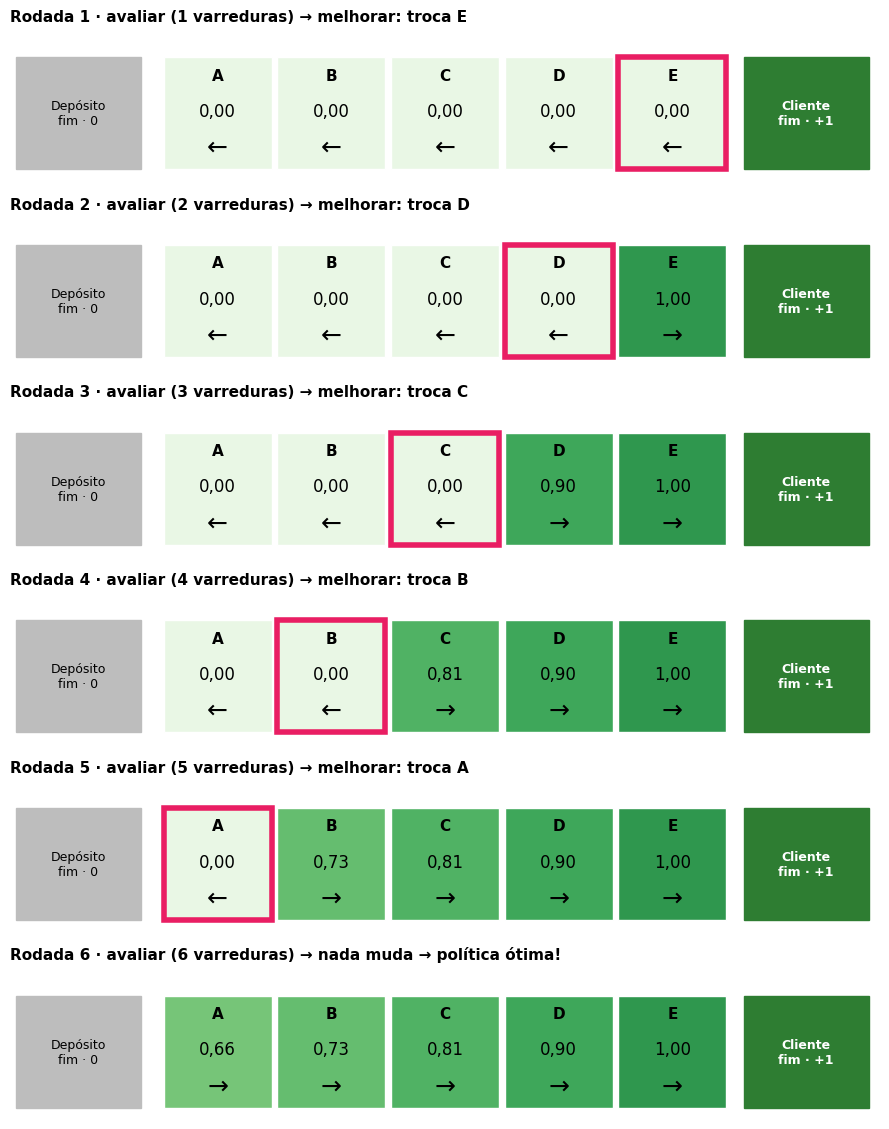

Regra inicial "← ← ← ← ←": 6 rodada(s) até a política ótima.


In [7]:
mostrar_treinador('← ← ← ← ←')   # 👈 troque à vontade: 5 setas, → ou ←

**🔎 Cartógrafo × Treinador (slide 80)**

| | 🗺️ Value Iteration | 🔧 Policy Iteration |
|---|---|---|
| Cada rodada | 1 varredura barata (com max) | avaliação completa (muitas varreduras) + 1 melhoria |
| Nº de rodadas | muitas | poucas, se o palpite inicial for bom |
| O que estabiliza primeiro | os valores | **a política** |

**O limite dos dois:** ambos precisam do **mapa** (a função `passo`, ou seja, P e R). E se o entregador não tiver mapa nenhum? → Monte Carlo e TD.

---
## 3. 🍽️ O Crítico — Monte Carlo (slide 81)

**Mudança de cenário:** agora o entregador **perdeu o mapa** e a bicicleta está desgovernada. A cada minuto ela vai para a esquerda ou para a direita, **50% / 50%**. Ele começa em C.

A pergunta passa a ser: **partindo de cada quarteirão, qual a chance de chegar ao Cliente?** (com γ = 1, esse é o valor V(s)).

O **Crítico** é como quem avalia um restaurante: só dá a nota **depois de comer a refeição inteira**.

1. Jogue o episódio **até o fim**.
2. Calcule o retorno **G** de cada quarteirão visitado: aqui, 1 se terminou no Cliente e 0 se terminou no Depósito.
3. **V(s) = média** das notas que s já recebeu.

> Esses agentes só **avaliam** a política da moeda. Aprender a **escolher** a ação sem mapa é o próximo passo: o Q-Learning.

In [8]:
def episodio(rng):
    '''Um passeio da bicicleta desgovernada, de C até o fim. Devolve [(quarteirão, recompensa), ...].'''
    s, passos = 2, []
    while 0 <= s < N:
        s2 = s + (1 if rng.random() < .5 else -1)
        r = 1.0 if s2 == N else 0.0
        passos.append((s, r))
        s = s2
    return passos


rng = np.random.default_rng(3)
passos = episodio(rng)
G = sum(r for _, r in passos)           # γ = 1: o retorno é a soma das recompensas
fim = 'Cliente (+1)' if G else 'Depósito (0)'
print('🚲 Trajeto:', ' → '.join(NOMES[s] for s, _ in passos), '→', fim)
print(f'🧾 Retorno do episódio: G = {G:.0f}\n')
print('🍽️ O Crítico anota no caderninho (uma nota por visita):')
for s in sorted(set(s for s, _ in passos)):
    vezes = sum(1 for x, _ in passos if x == s)
    print(f'   {NOMES[s]}: {vezes} × nota {G:.0f}')

🚲 Trajeto: C → D → E → D → C → D → E → Cliente (+1)
🧾 Retorno do episódio: G = 1

🍽️ O Crítico anota no caderninho (uma nota por visita):
   C: 2 × nota 1
   D: 3 × nota 1
   E: 2 × nota 1


> 🤔 **Palpite:** depois de **só esse** episódio, quanto o Crítico acha que vale o quarteirão C? Está certo?

O valor verdadeiro dá para calcular na mão: **A = 1/6, B = 2/6, C = 3/6, D = 4/6, E = 5/6**. Vamos ver o Crítico chegando lá, episódio após episódio.

 episódios       A       B       C       D       E
         1    1,00    1,00    1,00    1,00    1,00
        10    0,25    0,43    0,40    0,33    0,71
       100    0,29    0,49    0,60    0,74    0,90
      1000    0,16    0,30    0,46    0,62    0,80
      3000    0,16    0,33    0,49    0,65    0,81
   verdade    0,17    0,33    0,50    0,67    0,83


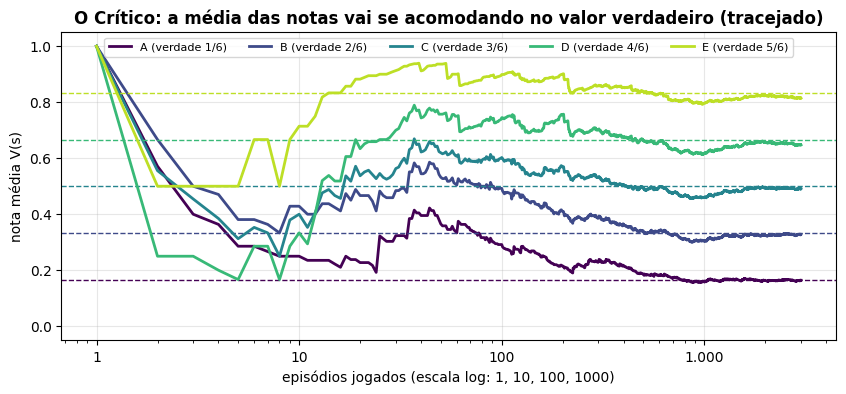

In [9]:
V_REAL = np.arange(1, N + 1) / (N + 1)    # 1/6 ... 5/6 (só para comparar: o Crítico não vê isto)


def critico(n_episodios, seed=1):
    '''Monte Carlo pela média: soma das notas ÷ número de notas, para cada quarteirão.'''
    rng = np.random.default_rng(seed)
    soma, contagem = np.zeros(N), np.zeros(N)
    historia = np.full((n_episodios, N), np.nan)
    for ep in range(n_episodios):
        passos = episodio(rng)
        G = sum(r for _, r in passos)
        for s, _ in passos:
            soma[s] += G
            contagem[s] += 1
        historia[ep] = np.where(contagem > 0, soma / np.maximum(contagem, 1), np.nan)
    return historia


historia = critico(3000)
print(f"{'episódios':>10}" + ''.join(f'{n:>8}' for n in NOMES))
for n in [1, 10, 100, 1000, 3000]:
    print(f'{n:>10}' + ''.join(f'{"  —" if np.isnan(v) else br(v):>8}' for v in historia[n - 1]))
print(f"{'verdade':>10}" + ''.join(f'{br(v):>8}' for v in V_REAL))

fig, ax = plt.subplots(figsize=(10, 4))
cores = plt.cm.viridis(np.linspace(0, .9, N))
for s in range(N):
    ax.plot(range(1, len(historia) + 1), historia[:, s], color=cores[s], lw=2, label=f'{NOMES[s]} (verdade {s + 1}/6)')
    ax.axhline(V_REAL[s], color=cores[s], ls='--', lw=1)
ax.set_xscale('log'); ax.set_ylim(-.05, 1.05)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'.replace(',', '.')))
ax.set_xlabel('episódios jogados (escala log: 1, 10, 100, 1000)'); ax.set_ylabel('nota média V(s)')
ax.set_title('O Crítico: a média das notas vai se acomodando no valor verdadeiro (tracejado)', fontweight='bold')
ax.legend(fontsize=8, ncol=5, loc='upper center'); ax.grid(alpha=.3)
plt.show()

**🔎 O que observar**
- **Começo maluco:** depois de 1 episódio, os quarteirões visitados recebem nota 0 ou 1, tudo ou nada. É a **variância alta** do slide 81: uma partida atípica distorce a média.
- **Com centenas de episódios,** as médias se acomodam no valor verdadeiro. É a Lei dos Grandes Números, a mesma do clima de longo prazo no notebook de Markov.
- **Sem mapa nenhum:** o Crítico nunca usou a função `passo`. Aprendeu só jogando.
- **O limite:** ele **precisa que o episódio acabe** para dar a nota. Numa tarefa sem fim, ele nunca aprenderia nada.

> **Truque que usaremos na seção 5:** a média pode ser atualizada sem guardar todas as notas, com $V \leftarrow V + \frac{1}{n}(G - V)$. Trocando $\frac{1}{n}$ por um α fixo, chega-se ao Monte Carlo "com α", que vai correr contra o TD.

---
## 4. 🚗 O Motorista — Diferença Temporal (slides 83 e 84) · item 1 do slide 85

O Motorista **não espera chegar**. Ele corrige a previsão **a cada esquina**, usando a própria previsão seguinte como alvo:

$$V(s) \leftarrow V(s) + \alpha\,\big[\,\underbrace{R + \gamma\,V(s')}_{\text{o que acabei de ver}} - \underbrace{V(s)}_{\text{o que eu achava}}\,\big]$$

A diferença entre os dois é o **erro TD**, a "surpresa". α diz quanto dessa surpresa eu aceito de cada vez.

### A conta do slide 84: a volta para casa

Aqui a "recompensa" é o **tempo gasto**, com γ = 1 e α = 0,5.

| | |
|---|---|
| 🏢 Saí do trabalho | palpite: V(trabalho) = **40 min** |
| 🚦 Trânsito na 1ª esquina! | já gastei **R = 15 min**; daqui faltam **V(s′) = 35 min** |

In [10]:
def atualizacao_td(V_s, R, V_prox, alfa, gamma=1.0):
    '''Uma atualização TD(0). Devolve (novo valor, erro TD).'''
    erro_td = R + gamma * V_prox - V_s
    return V_s + alfa * erro_td, erro_td


novo, erro = atualizacao_td(V_s=40, R=15, V_prox=35, alfa=0.5)
print('😲 A surpresa:  R + V(s\') = 15 + 35 = 50   →   erro TD = 50 − 40 =', f'{erro:+.0f}')
print(f'✏️ Corrijo já:  V = 40 + 0,5 × {erro:.0f} = {br(novo, 0)} min')

😲 A surpresa:  R + V(s') = 15 + 35 = 50   →   erro TD = 50 − 40 = +10
✏️ Corrijo já:  V = 40 + 0,5 × 10 = 45 min


> 🤔 **Desafio relâmpago (slide 84):** com α = 0,1, qual seria o novo V(trabalho)? E com α = 1? Calculem antes de rodar.

In [11]:
for alfa in [0.1, 0.5, 1.0]:
    novo, _ = atualizacao_td(40, 15, 35, alfa)
    print(f'α = {br(alfa, 1)}  →  V(trabalho) = {br(novo, 1)} min')
print('\nα = 1 joga fora o palpite antigo e confia 100% na novidade; α = 0,1 desconfia e anda só um pouquinho.')

α = 0,1  →  V(trabalho) = 41,0 min
α = 0,5  →  V(trabalho) = 45,0 min
α = 1,0  →  V(trabalho) = 50,0 min

α = 1 joga fora o palpite antigo e confia 100% na novidade; α = 0,1 desconfia e anda só um pouquinho.


### A viagem inteira: Monte Carlo × TD

A viagem continua. Em cada ponto, o motorista olha o relógio e refaz a previsão do **total**: o tempo decorrido + quanto ainda falta.

| Ponto da viagem | Decorrido | Previsão de quanto falta | Previsão do total |
|---|---|---|---|
| 🏢 Saindo do trabalho | 0 | 40 | 40 |
| 🚦 1ª esquina: trânsito! | 15 | 35 | 50 |
| 🛣️ Entrou na marginal, fluindo | 25 | 15 | 40 |
| 💥 Acidente na saída da marginal | 35 | 15 | 50 |
| 🏘️ Rua de casa | 51 | 4 | 55 |
| 🏠 **Chegou** | **55** | 0 | **55** |

- **🍽️ Monte Carlo** espera chegar (55 min) e só então corrige **todas** as previsões rumo ao real.
- **🚗 TD** corrige cada previsão **já no ponto seguinte**, rumo à próxima previsão.

> 🤔 **Palpite (slide 85):** na **1ª esquina**, para que lado cada um puxa a previsão: para cima ou para baixo?

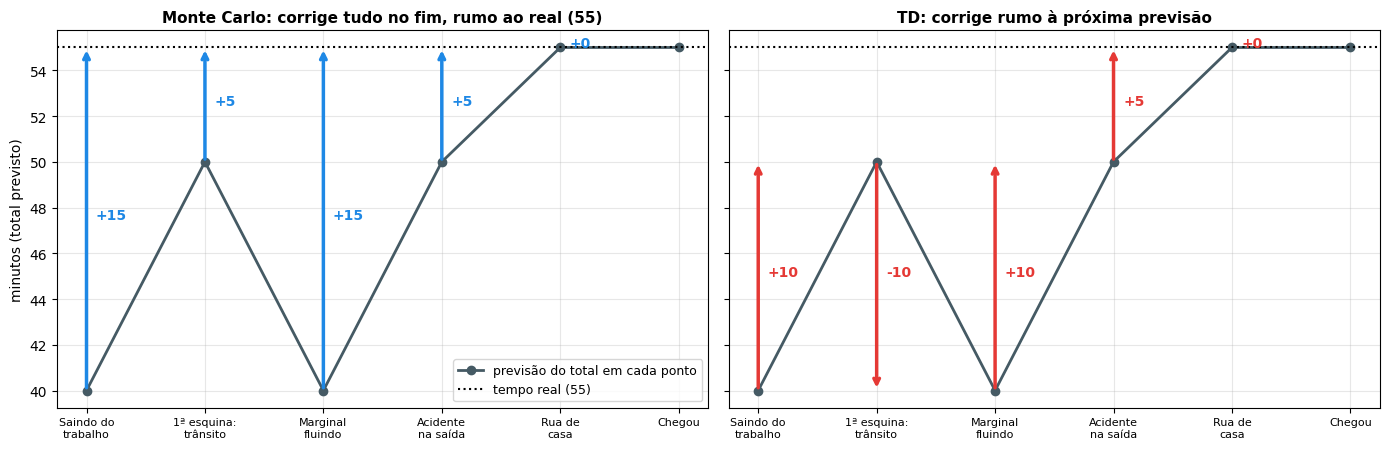

Correção sugerida em cada ponto (alvo − previsão):
ponto                         Monte Carlo     TD
Saindo do trabalho                    +15    +10
1ª esquina: trânsito                   +5    -10
Marginal fluindo                      +15    +10
Acidente na saída                      +5     +5
Rua de casa                            +0     +0


In [12]:
pontos = ['Saindo do\ntrabalho', '1ª esquina:\ntrânsito', 'Marginal\nfluindo', 'Acidente\nna saída', 'Rua de\ncasa', 'Chegou']
previsao_total = np.array([40, 50, 40, 50, 55, 55])   # decorrido + previsão de quanto falta
real = 55

alvo_mc = np.full(5, real)            # MC: o resultado final, para todos
alvo_td = previsao_total[1:]          # TD: a previsão do ponto seguinte

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for ax, alvo, titulo, cor in [(axes[0], alvo_mc, 'Monte Carlo: corrige tudo no fim, rumo ao real (55)', '#1E88E5'),
                              (axes[1], alvo_td, 'TD: corrige rumo à próxima previsão', '#E53935')]:
    ax.plot(range(6), previsao_total, 'o-', color='#455A64', lw=2, label='previsão do total em cada ponto')
    ax.axhline(real, color='k', ls=':', label='tempo real (55)')
    for i in range(5):
        ax.annotate('', xy=(i, alvo[i]), xytext=(i, previsao_total[i]),
                    arrowprops=dict(arrowstyle='->', color=cor, lw=2.5))
        ax.text(i + .08, (alvo[i] + previsao_total[i]) / 2, f'{alvo[i] - previsao_total[i]:+d}', color=cor, fontweight='bold')
    ax.set_xticks(range(6), pontos, fontsize=8)
    ax.set_title(titulo, fontsize=11, fontweight='bold')
    ax.grid(alpha=.3)
axes[0].set_ylabel('minutos (total previsto)')
axes[0].legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

print("Correção sugerida em cada ponto (alvo − previsão):")
print(f"{'ponto':28s} {'Monte Carlo':>12s} {'TD':>6s}")
for i in range(5):
    print(f"{pontos[i].replace(chr(10), ' '):28s} {alvo_mc[i] - previsao_total[i]:+12d} {alvo_td[i] - previsao_total[i]:+6d}")

**🔎 O que observar**
- **"Saindo do trabalho":** o TD corrige **+10 já na 1ª esquina**, a conta do slide 84, sem saber como a viagem termina. O MC só corrige (+15) depois de chegar em casa.
- **"1ª esquina": os dois discordam.** O TD puxa para **baixo** (−10), porque no ponto seguinte a marginal estava fluindo. O MC puxa para **cima** (+5), porque já sabe que a viagem acabou em 55. O TD reage ao que vê agora; o MC, ao resultado final.
- O TD aprende com a **própria próxima estimativa**, e isso se chama *bootstrapping* (slide 82).

---
## 5. Crítico × Motorista: o passeio na avenida (slide 82) · item 2 do slide 85

De volta à bicicleta desgovernada da seção 3. Agora os dois aprendem **lado a lado**, com os **mesmos episódios** (mesma sorte) e α = 0,1. Os dois começam achando que todo quarteirão vale 0,5.

> 🤔 **Palpite:** num episódio que termina no **Depósito**, quantos quarteirões cada um altera? Qual estimativa "pula" mais?

In [13]:
def monte_carlo(V, passos, alfa):
    '''🍽️ Espera o fim: cada quarteirão visitado anda rumo ao retorno REAL G.'''
    G = sum(r for _, r in passos)
    for s, _ in passos:
        V[s] += alfa * (G - V[s])


def td0(V, passos, alfa):
    '''🚗 A cada passo: o alvo é a recompensa + o valor estimado do próximo quarteirão.'''
    for k, (s, r) in enumerate(passos):
        v_prox = V[passos[k + 1][0]] if k + 1 < len(passos) else 0.0   # fim: não há futuro
        V[s] += alfa * (r + v_prox - V[s])

In [14]:
# @title ▶️ Animação: os dois aprendendo (rode e use os botões ◀ ▶)
rng = np.random.default_rng(0)
V_mc, V_td = np.full(N, .5), np.full(N, .5)
fotos = [(0, V_mc.copy(), V_td.copy(), '')]
for ep in range(1, 101):
    passos = episodio(rng)
    monte_carlo(V_mc, passos, .1)
    td0(V_td, passos, .1)
    if ep <= 10 or ep % 10 == 0:
        fim = 'Cliente (+1)' if passos[-1][1] else 'Depósito (0)'
        fotos.append((ep, V_mc.copy(), V_td.copy(), ' '.join(NOMES[s] for s, _ in passos) + f' → {fim}'))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), dpi=65, sharey=True)
fig.subplots_adjust(top=.78, bottom=.12, wspace=.08)


def quadro(k):
    ep, vm, vt, trajeto = fotos[min(k, len(fotos) - 1)]
    for ax, V, nome, cor in [(axes[0], vm, 'Monte Carlo (Crítico)', '#1E88E5'), (axes[1], vt, 'TD (Motorista)', '#E53935')]:
        ax.clear()
        ax.plot(range(N), V_REAL, 'k--', marker='o', label='valor verdadeiro')
        ax.plot(range(N), V, '-o', color=cor, lw=2.5, label=nome)
        ax.set_xticks(range(N), NOMES); ax.set_ylim(0, 1); ax.grid(alpha=.3)
        erro = np.sqrt(np.mean((V - V_REAL) ** 2))
        ax.set_title(f'{nome} · erro {br(erro, 3)}', fontweight='bold', color=cor)
        ax.legend(loc='upper left', fontsize=8)
    axes[0].set_ylabel('valor estimado V(s)')
    fig.suptitle(f'Depois de {ep} episódio(s)' + (f'\núltimo: {trajeto}' if trajeto else ''), fontsize=11)
    return []


anim = animation.FuncAnimation(fig, quadro, frames=len(fotos) + 3, interval=700)
plt.close(fig)
HTML(anim.to_jshtml(default_mode='once'))

**🔎 O que observar**
- **Episódio que termina no Depósito:** o Monte Carlo puxa **todos** os quarteirões visitados para 0, porque o retorno foi 0. O TD mexe pouco: só o último quarteirão, que viu o fim de perto, cai.
- **O TD espalha a informação de vizinho para vizinho,** como o boato do Cartógrafo, só que aprendendo jogando, sem mapa. É também o valor que "vaza para trás" na cobrinha (slide 104).
- **O Monte Carlo pula mais:** cada episódio é uma moeda, 0 ou 1. Isso é a **variância alta** do slide 82. O TD pula menos, mas depende das próprias estimativas, que podem estar erradas (o "algum viés").

---
## 6. 🏁 A corrida: quem erra menos? · item 3 do slide 85

São 100 corridas de 100 episódios para cada método e para três valores de α. A medida é o **erro médio** entre o valor estimado e o verdadeiro: quanto menor, melhor.

> 🤔 **Palpite:** quem termina com menos erro, o Crítico ou o Motorista? α grande ajuda ou atrapalha?

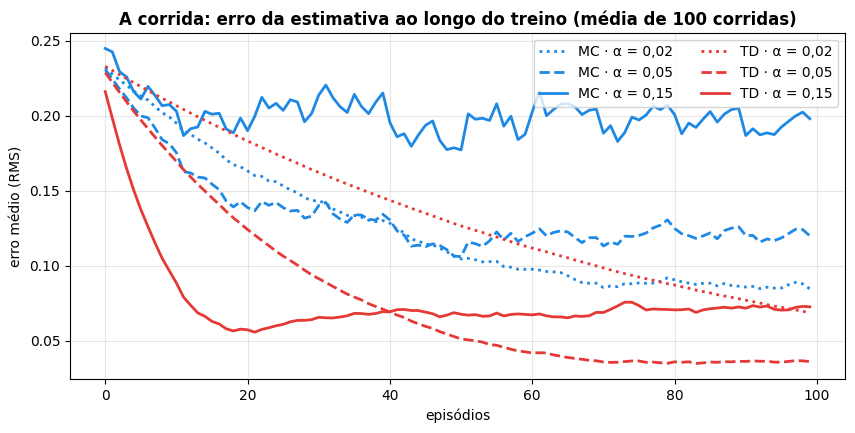

método     α  erro após 10 ep.  erro após 100 ep.
MC      0,02             0,199              0,085
MC      0,05             0,181              0,120
MC      0,15             0,207              0,198
TD      0,02             0,209              0,069
TD      0,05             0,175              0,036
TD      0,15             0,097              0,073

🏆 Menor erro final: TD com α = 0,05


In [15]:
def curva_de_erro(metodo, alfa, n_corridas=100, n_episodios=100):
    erros = np.zeros(n_episodios)
    for corrida in range(n_corridas):
        rng = np.random.default_rng(corrida)
        V = np.full(N, .5)
        for ep in range(n_episodios):
            metodo(V, episodio(rng), alfa)
            erros[ep] += np.sqrt(np.mean((V - V_REAL) ** 2))
    return erros / n_corridas


fig, ax = plt.subplots(figsize=(10, 4.5))
resumo = []
for metodo, nome, cor in [(monte_carlo, 'MC', '#1E88E5'), (td0, 'TD', '#E53935')]:
    for alfa, estilo in [(.02, ':'), (.05, '--'), (.15, '-')]:
        erro = curva_de_erro(metodo, alfa)
        ax.plot(erro, estilo, color=cor, lw=2, label=f'{nome} · α = {br(alfa)}')
        resumo.append((nome, alfa, erro[9], erro[-1]))
ax.set_xlabel('episódios'); ax.set_ylabel('erro médio (RMS)')
ax.set_title('A corrida: erro da estimativa ao longo do treino (média de 100 corridas)', fontweight='bold')
ax.grid(alpha=.3); ax.legend(ncol=2)
plt.show()

print(f"{'método':6s} {'α':>5s} {'erro após 10 ep.':>17s} {'erro após 100 ep.':>18s}")
for nome, alfa, e10, e100 in resumo:
    print(f"{nome:6s} {br(alfa):>5s} {br(e10, 3):>17s} {br(e100, 3):>18s}")
vencedor = min(resumo, key=lambda x: x[3])
print(f'\n🏆 Menor erro final: {vencedor[0]} com α = {br(vencedor[1])}')

**🔎 O que observar**
- **Nesta avenida, o TD aprende mais rápido e termina com menos erro** que o Monte Carlo, para o mesmo α. É o resultado clássico de Sutton & Barto (exemplo 6.2).
- **α grande** aprende rápido no começo, mas a estimativa fica "tremendo" e o erro para de cair. **α pequeno** é estável, porém lento. É o mesmo dilema do "Mexa no α" do Q-Learning (slide 106).
- **A vantagem que não aparece aqui:** o TD **não precisa que o episódio termine**. Um robô de armazém que trabalha sem parar nunca "chega ao fim", e só o TD consegue aprender nele.

---
## 🏆 Placar final: os quatro entregadores

| | Personagem | Precisa do mapa? | Quando corrige | O que vimos aqui |
|---|---|---|---|---|
| 🗺️ | Cartógrafo (Value Iteration) | sim | antes de andar, rodada a rodada | o boato chega a A na rodada 5 |
| 🔧 | Treinador (Policy Iteration) | sim | avalia a regra inteira, depois melhora | conserta a regra do chefe em 2 rodadas |
| 🍽️ | Crítico (Monte Carlo) | **não** | no **fim** do episódio | sem viés, mas pula muito no começo |
| 🚗 | Motorista (TD) | **não** | a **cada passo** | aprende mais rápido nesta avenida |

**Todos buscam o mesmo prêmio (slide 77):** V\* e π\*. Muda só o caminho até lá.

## 💭 Para pensar (em dupla)

1. **Mapa ou não?** Num app de entregas, o que seria "ter o mapa" (P e R)? Dá para ter isso no mundo real, ou o agente precisa aprender jogando?
2. **Slide 82:** "MC: sem viés, mas variância alta". Onde você **viu** a variância alta: no gráfico do Crítico (seção 3) ou na animação (seção 5)?
3. **Bootstrapping:** o TD usa a **própria estimativa** como alvo. Se ela estiver errada, o alvo também está. Por que, mesmo assim, ele funciona?
4. **Ponte com o Q-Learning:** compare a regra do TD, $V(s) \leftarrow V(s) + \alpha[R + \gamma V(s') - V(s)]$, com a do Q-Learning (slide 96). O que mudou?
5. **Negócio (slide 82):** para ajustar ofertas a clientes que **nunca "terminam"** o relacionamento, qual dos dois serve: o Crítico ou o Motorista? Por quê?